# IDRiD: VGG-16 and ResNet-18 — From Scratch vs Transfer Learning (Colab Ready)

**Objective:** Compare VGG-16 and ResNet-18 trained from random initialisation against the same architectures initialised with ImageNet pretrained weights and fine-tuned on the IDRiD diabetic retinopathy dataset.

Four experiments:
1. VGG-16 — scratch
2. VGG-16 — pretrained and fine-tuned
3. ResNet-18 — scratch
4. ResNet-18 — pretrained and fine-tuned

**Colab / Kaggle setup:** In Google Colab, select **Runtime -> Change runtime type -> T4 GPU** (or better), mount Google Drive or download the dataset via `kagglehub` / Kaggle API, and verify `BASE_PATH` before running.

## 1. Install and import libraries

In [3]:
!pip install -q scikit-learn seaborn

import os
import copy
import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, cohen_kappa_score
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cpu


## 2. Configure IDRiD paths & output directory
Update `BASE_PATH` and `WORK_DIR` if running on Google Colab (for example, mounting Drive or downloading with `kagglehub`).

In [4]:
import zipfile
from pathlib import Path
import pandas as pd

WORK_DIR = Path("/content/outputs")
WORK_DIR.mkdir(parents=True, exist_ok=True)

# Look for archive (3).zip or any zip in /content
zip_candidates = sorted(Path("/content").glob("*.zip"))
assert zip_candidates, (
    "No .zip file found in /content. Upload 'archive (3).zip' to /content first "
    "(or set ZIP_PATH to its exact path)."
)

ZIP_PATH = zip_candidates[0]
EXTRACT_DIR = Path("/content/idrid_data")

print("Using zip file:", ZIP_PATH)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
  zf.extractall(EXTRACT_DIR)
print("Extracted to:", EXTRACT_DIR)

# Locate B.%20Disease%20Grading (or B. Disease Grading)
grading_dirs = [
    p
    for p in EXTRACT_DIR.rglob("*")
    if p.is_dir() and "disease" in p.name.lower() and "grading" in p.name.lower()
]
assert grading_dirs, (
    f"Could not find Disease Grading folder inside {EXTRACT_DIR}."
)

# If nested (e.g. B.%20Disease%20Grading/B.%20Disease%20Grading), pick the innermost one with '1. Original Images'
BASE_PATH = None
for d in sorted(grading_dirs, key=lambda x: len(x.parts), reverse=True):
  if (d / "1. Original Images").exists():
    BASE_PATH = d
    break
assert BASE_PATH is not None, (
    f"Found Disease Grading folder {grading_dirs[0]}, but '1. Original Images' was not inside it."
)
print("Detected BASE_PATH:", BASE_PATH)

train_img_candidates = list(
    (BASE_PATH / "1. Original Images").glob("*Training*")
)
test_img_candidates = list((BASE_PATH / "1. Original Images").glob("*Testing*"))

train_csv_candidates = [
    p
    for p in BASE_PATH.rglob("*.csv")
    if "train" in p.name.lower()
    and ("grading" in p.name.lower() or "label" in p.name.lower())
]
test_csv_candidates = [
    p
    for p in BASE_PATH.rglob("*.csv")
    if "test" in p.name.lower()
    and ("grading" in p.name.lower() or "label" in p.name.lower())
]

assert train_img_candidates, (
    f"Training image folder not found under {BASE_PATH / '1. Original Images'}"
)
assert test_img_candidates, (
    f"Testing image folder not found under {BASE_PATH / '1. Original Images'}"
)
assert train_csv_candidates, (
    f"Training labels CSV not found under {BASE_PATH}"
)
assert test_csv_candidates, f"Testing labels CSV not found under {BASE_PATH}"

train_img_dir = train_img_candidates[0]
test_img_dir = test_img_candidates[0]
train_csv_path = train_csv_candidates[0]
test_csv_path = test_csv_candidates[0]

for path in [train_img_dir, test_img_dir, train_csv_path, test_csv_path]:
  print(path, "->", path.exists())

train_df = pd.read_csv(train_csv_path)
test_df = pd.read_csv(test_csv_path)

print("Train:", train_df.shape)
print("Test:", test_df.shape)
display(train_df.head())

Using zip file: /content/archive (3).zip
Extracted to: /content/idrid_data
Detected BASE_PATH: /content/idrid_data/B.%20Disease%20Grading/B. Disease Grading
/content/idrid_data/B.%20Disease%20Grading/B. Disease Grading/1. Original Images/a. Training Set -> True
/content/idrid_data/B.%20Disease%20Grading/B. Disease Grading/1. Original Images/b. Testing Set -> True
/content/idrid_data/B.%20Disease%20Grading/B. Disease Grading/2. Groundtruths/a. IDRiD_Disease Grading_Training Labels.csv -> True
/content/idrid_data/B.%20Disease%20Grading/B. Disease Grading/2. Groundtruths/b. IDRiD_Disease Grading_Testing Labels.csv -> True
Train: (413, 12)
Test: (103, 3)


,Image name,Retinopathy grade,Risk of macular edema,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11
0,IDRiD_001,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IDRiD_002,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IDRiD_003,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,IDRiD_004,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IDRiD_005,4,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Inspect labels and resolve image filenames

Training class distribution:


,count
Retinopathy grade,
0,134
1,20
2,136
3,74
4,49


Testing class distribution:


,count
Retinopathy grade,
0,34
1,5
2,32
3,19
4,13


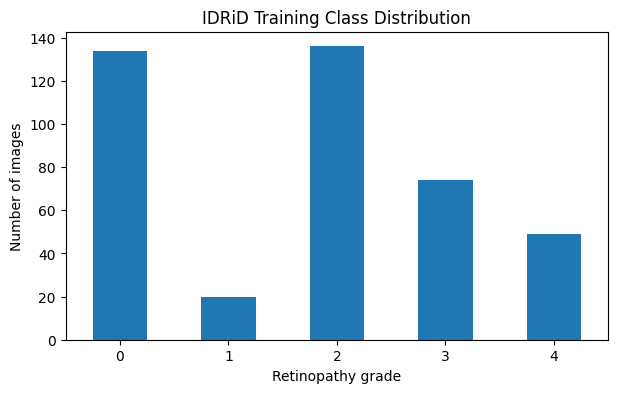

In [5]:
IMAGE_EXTENSIONS = [".jpg", ".jpeg", ".png", ".tif", ".tiff"]

def find_image_path(image_name, image_dir):
    image_name = str(image_name).strip()
    candidate = Path(image_name)
    if candidate.suffix:
        full_path = Path(image_dir) / candidate.name
        if full_path.exists():
            return str(full_path)

    stem = candidate.stem
    for ext in IMAGE_EXTENSIONS:
        full_path = Path(image_dir) / f"{stem}{ext}"
        if full_path.exists():
            return str(full_path)

    raise FileNotFoundError(
        f"Image '{image_name}' not found in '{image_dir}'. "
        "Check the CSV filenames and image folder."
    )

required = ["Image name", "Retinopathy grade"]
for df in [train_df, test_df]:
    missing = set(required) - set(df.columns)
    assert not missing, f"CSV is missing columns: {missing}"

train_df = train_df.dropna(subset=required).copy()
test_df = test_df.dropna(subset=required).copy()
train_df["Retinopathy grade"] = train_df["Retinopathy grade"].astype(int)
test_df["Retinopathy grade"] = test_df["Retinopathy grade"].astype(int)

train_df["image_path"] = train_df["Image name"].apply(
    lambda x: find_image_path(x, train_img_dir)
)
test_df["image_path"] = test_df["Image name"].apply(
    lambda x: find_image_path(x, test_img_dir)
)

NUM_CLASSES = 5
assert set(train_df["Retinopathy grade"].unique()).issubset(set(range(NUM_CLASSES)))
assert set(test_df["Retinopathy grade"].unique()).issubset(set(range(NUM_CLASSES)))

print("Training class distribution:")
display(train_df["Retinopathy grade"].value_counts().sort_index().rename("count"))
print("Testing class distribution:")
display(test_df["Retinopathy grade"].value_counts().sort_index().rename("count"))

train_df["Retinopathy grade"].value_counts().sort_index().plot(
    kind="bar", figsize=(7, 4), title="IDRiD Training Class Distribution"
)
plt.xlabel("Retinopathy grade")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.show()

## 4. Create a stratified training/validation split

In [6]:
train_part, val_part = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_df["Retinopathy grade"]
)

train_part = train_part.reset_index(drop=True)
val_part = val_part.reset_index(drop=True)
test_part = test_df.reset_index(drop=True)

print("Training images:", len(train_part))
print("Validation images:", len(val_part))
print("Testing images:", len(test_part))

Training images: 330
Validation images: 83
Testing images: 103


## 5. Image transformations and Dataset

In [18]:
import time
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0
EPOCHS = 4
PATIENCE = 2

imagenet_mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
imagenet_std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def cache_split_to_ram(df):
    imgs = []
    for img_path in df["image_path"]:
        with Image.open(img_path) as img:
            img = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
            imgs.append(torch.from_numpy(np.asarray(img, dtype=np.uint8)).permute(2, 0, 1))
    x_u8 = torch.stack(imgs, dim=0)
    y = torch.tensor(df["Retinopathy grade"].astype(int).to_numpy(), dtype=torch.long)
    return x_u8, y

t0 = time.time()
X_train_u8, y_train = cache_split_to_ram(train_part)
X_val_u8, y_val = cache_split_to_ram(val_part)
X_test_u8, y_test = cache_split_to_ram(test_part)
print(f"RAM cache built in {time.time() - t0:.1f}s")

class FastIDRiDRAMDataset(Dataset):
    def __init__(self, x_u8, y, augment=False):
        self.x_u8 = x_u8
        self.y = y
        self.augment = augment
        self.aug = transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(degrees=12),
        ])

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.x_u8[idx].float().div_(255.0)
        if self.augment:
            x = self.aug(x)
        x = (x - imagenet_mean) / imagenet_std
        return x, self.y[idx]

use_cuda = device.type == "cuda"
train_loader = DataLoader(
    FastIDRiDRAMDataset(X_train_u8, y_train, augment=True),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=use_cuda
)
val_loader = DataLoader(
    FastIDRiDRAMDataset(X_val_u8, y_val, augment=False),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=use_cuda
)
test_loader = DataLoader(
    FastIDRiDRAMDataset(X_test_u8, y_test, augment=False),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=use_cuda
)

RAM cache built in 38.6s


## 6. Handle class imbalance

In [19]:
observed_classes = np.sort(train_part["Retinopathy grade"].unique())
weights_array = compute_class_weight(
    class_weight="balanced",
    classes=observed_classes,
    y=train_part["Retinopathy grade"].to_numpy()
)
class_weights = torch.ones(NUM_CLASSES, dtype=torch.float32)
for cls, weight in zip(observed_classes, weights_array):
    class_weights[int(cls)] = float(weight)

class_weights = class_weights.to(device)
print("Class weights:", class_weights)

Class weights: tensor([0.6168, 4.1250, 0.6055, 1.1186, 1.6923])


## 7. Define VGG-16 and ResNet-18

In [20]:
def build_model(architecture, pretrained=False):
    if architecture == "VGG16":
        weights = models.VGG16_Weights.DEFAULT if pretrained else None
        model = models.vgg16(weights=weights)
        in_features = model.classifier[6].in_features
        model.classifier[6] = nn.Linear(in_features, NUM_CLASSES)

    elif architecture == "ResNet18":
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        model = models.resnet18(weights=weights)
        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, NUM_CLASSES)

    else:
        raise ValueError("Architecture must be VGG16 or ResNet18")

    return model.to(device)

## 8. Training and evaluation functions

In [21]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()

    running_loss = 0.0
    all_labels, all_preds = [], []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            with torch.amp.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                logits = model(x)
                loss = criterion(logits, y)

            if is_training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        running_loss += loss.item() * x.size(0)
        preds = torch.argmax(logits, dim=1)
        all_labels.extend(y.detach().cpu().numpy())
        all_preds.extend(preds.detach().cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds, average="macro", zero_division=0)
    epoch_acc = accuracy_score(all_labels, all_preds)
    return epoch_loss, epoch_acc, epoch_f1


def train_model(
    model, model_name, epochs=20, learning_rate=1e-4,
    patience=5, save_dir=None
):
    if save_dir is None:
        save_dir = str(WORK_DIR / "checkpoints")
    os.makedirs(save_dir, exist_ok=True)
    checkpoint_path = os.path.join(save_dir, f"{model_name}_best.pth")

    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=learning_rate, weight_decay=1e-4
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2
    )
    scaler = torch.amp.GradScaler(
        device.type, enabled=(device.type == "cuda")
    )

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": [],
        "train_f1": [], "val_f1": []
    }

    best_val_f1 = -1.0
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(epochs):
        start = time.time()

        train_loss, train_acc, train_f1 = run_epoch(
            model, train_loader, criterion, optimizer, scaler
        )
        val_loss, val_acc, val_f1 = run_epoch(
            model, val_loader, criterion
        )

        scheduler.step(val_f1)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["train_f1"].append(train_f1)
        history["val_f1"].append(val_f1)

        print(
            f"{model_name} | Epoch {epoch+1:02d}/{epochs} | "
            f"Train loss {train_loss:.4f} F1 {train_f1:.4f} | "
            f"Val loss {val_loss:.4f} F1 {val_f1:.4f} | "
            f"{time.time()-start:.1f}s"
        )

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, checkpoint_path)
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print("Early stopping.")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history, checkpoint_path


def predict_model(model, loader):
    model.eval()
    labels_all, preds_all, probs_all = [], [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            with torch.amp.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                logits = model(x)
            probs = torch.softmax(logits, dim=1)
            preds = probs.argmax(dim=1)

            labels_all.extend(y.numpy())
            preds_all.extend(preds.cpu().numpy())
            probs_all.extend(probs.cpu().numpy())

    return np.array(labels_all), np.array(preds_all), np.array(probs_all)


def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 (Macro)": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Quadratic Kappa": cohen_kappa_score(
            y_true, y_pred, weights="quadratic"
        )
    }

## 9. Train the four experiments

In [22]:
experiments = [
    {"name": "VGG16_Scratch", "architecture": "VGG16", "pretrained": False, "lr": 1e-4},
    {"name": "VGG16_Pretrained", "architecture": "VGG16", "pretrained": True, "lr": 1e-5},
    {"name": "ResNet18_Scratch", "architecture": "ResNet18", "pretrained": False, "lr": 1e-4},
    {"name": "ResNet18_Pretrained", "architecture": "ResNet18", "pretrained": True, "lr": 1e-5},
]

trained_models = {}
histories = {}
checkpoint_paths = {}

run_start = time.time()
for exp in experiments:
    print("\n" + "="*80)
    print("Starting:", exp["name"])
    print("="*80)

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    model = build_model(exp["architecture"], exp["pretrained"])

    model, history, checkpoint = train_model(
        model=model,
        model_name=exp["name"],
        epochs=EPOCHS,
        learning_rate=exp["lr"],
        patience=PATIENCE,
        save_dir=str(WORK_DIR / "checkpoints")
    )

    trained_models[exp["name"]] = model
    histories[exp["name"]] = history
    checkpoint_paths[exp["name"]] = checkpoint
    print(f"Elapsed so far: {(time.time() - run_start)/60:.1f} min")


Starting: VGG16_Scratch
VGG16_Scratch | Epoch 01/4 | Train loss 1.6345 F1 0.1860 | Val loss 1.6099 F1 0.0982 | 137.2s
VGG16_Scratch | Epoch 02/4 | Train loss 1.6115 F1 0.1018 | Val loss 1.6064 F1 0.0982 | 136.4s
VGG16_Scratch | Epoch 03/4 | Train loss 1.6085 F1 0.1183 | Val loss 1.6035 F1 0.1934 | 134.9s
VGG16_Scratch | Epoch 04/4 | Train loss 1.6063 F1 0.1663 | Val loss 1.5956 F1 0.1941 | 134.8s
Elapsed so far: 9.1 min

Starting: VGG16_Pretrained
VGG16_Pretrained | Epoch 01/4 | Train loss 1.6774 F1 0.2010 | Val loss 1.5322 F1 0.2765 | 135.4s
VGG16_Pretrained | Epoch 02/4 | Train loss 1.5291 F1 0.3046 | Val loss 1.4749 F1 0.3414 | 146.1s
VGG16_Pretrained | Epoch 03/4 | Train loss 1.4134 F1 0.3271 | Val loss 1.3929 F1 0.3499 | 138.9s
VGG16_Pretrained | Epoch 04/4 | Train loss 1.3593 F1 0.3481 | Val loss 1.3107 F1 0.4167 | 145.7s
Elapsed so far: 18.6 min

Starting: ResNet18_Scratch
ResNet18_Scratch | Epoch 01/4 | Train loss 1.5826 F1 0.2594 | Val loss 1.6164 F1 0.1556 | 18.3s
ResNet18_S

100%|██████████| 44.7M/44.7M [00:00<00:00, 89.0MB/s]


ResNet18_Pretrained | Epoch 01/4 | Train loss 1.6641 F1 0.1567 | Val loss 1.6046 F1 0.1631 | 17.5s
ResNet18_Pretrained | Epoch 02/4 | Train loss 1.4930 F1 0.2525 | Val loss 1.5304 F1 0.2463 | 17.5s
ResNet18_Pretrained | Epoch 03/4 | Train loss 1.3407 F1 0.3737 | Val loss 1.4508 F1 0.2816 | 16.8s
ResNet18_Pretrained | Epoch 04/4 | Train loss 1.2524 F1 0.3850 | Val loss 1.3831 F1 0.3091 | 17.2s
Elapsed so far: 21.0 min


## 10. Plot training curves

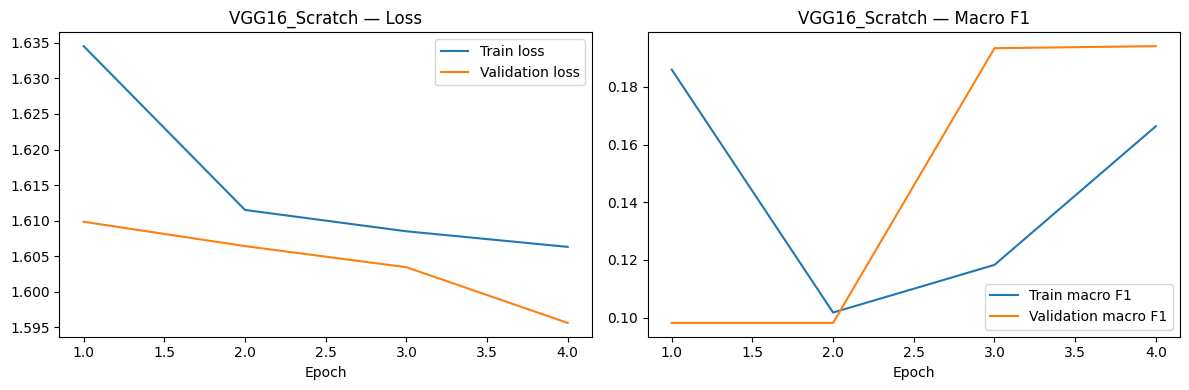

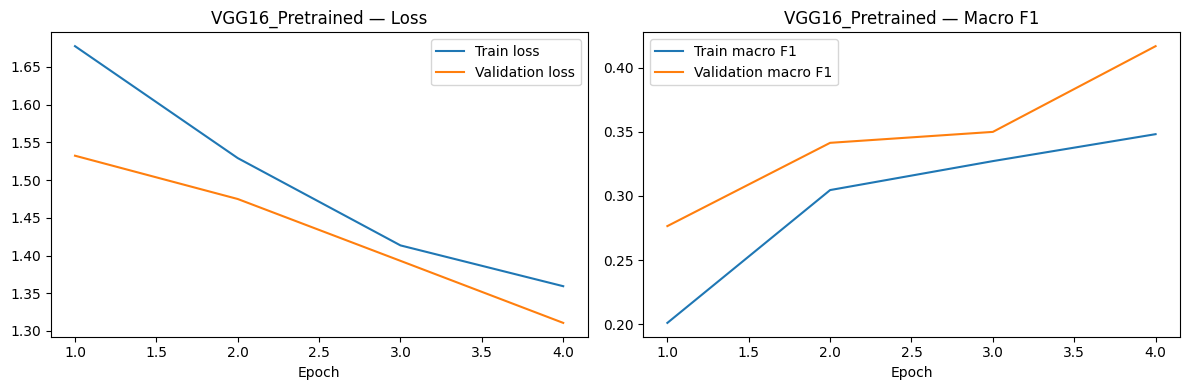

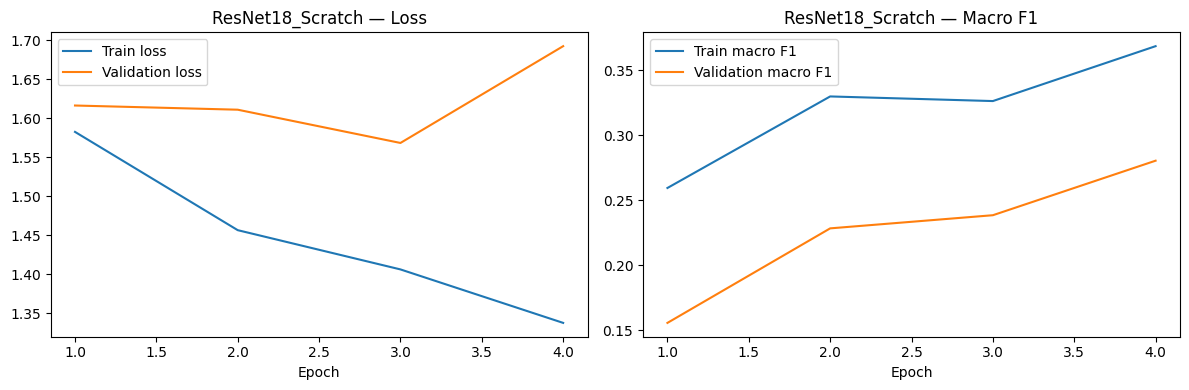

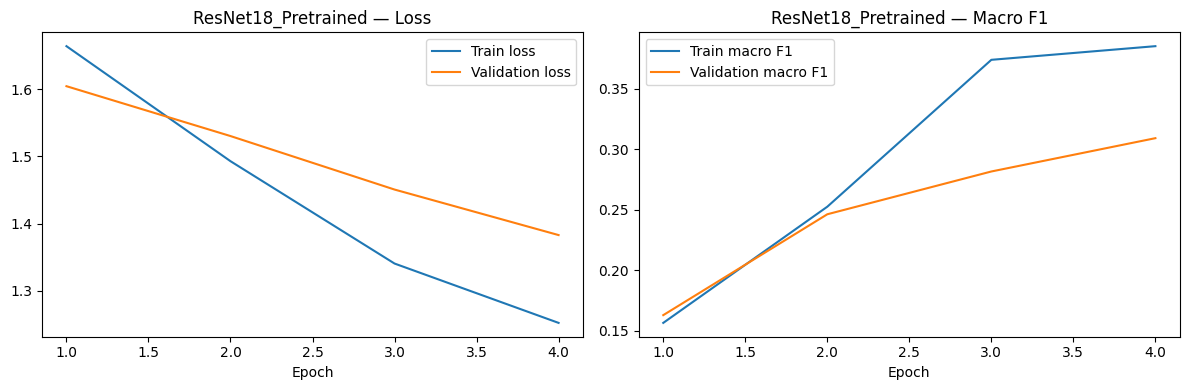

In [23]:
for name, history in histories.items():
    epochs_ran = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs_ran, history["train_loss"], label="Train loss")
    axes[0].plot(epochs_ran, history["val_loss"], label="Validation loss")
    axes[0].set_title(f"{name} — Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(epochs_ran, history["train_f1"], label="Train macro F1")
    axes[1].plot(epochs_ran, history["val_f1"], label="Validation macro F1")
    axes[1].set_title(f"{name} — Macro F1")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

## 11. Final evaluation on the held-out testing set & summary stats

In [25]:
test_results = []
test_predictions = {}

for name, model in trained_models.items():
    y_true, y_pred, y_prob = predict_model(model, test_loader)
    metrics = calculate_metrics(y_true, y_pred)
    metrics["Model"] = name
    test_results.append(metrics)
    test_predictions[name] = (y_true, y_pred, y_prob)

results_df = pd.DataFrame(test_results).set_index("Model")
display(results_df.round(4))

print("\n--- Summary Statistics Across Models (Test Set) ---")
display(results_df.describe().loc[["mean", "std", "min", "max"]].round(4))

,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),Quadratic Kappa
Model,,,,,
VGG16_Scratch,0.3107,0.1302,0.1974,0.1388,-0.0361
VGG16_Pretrained,0.3883,0.3222,0.3630,0.2990,0.5680
ResNet18_Scratch,0.2427,0.2859,0.1949,0.1867,0.2205
ResNet18_Pretrained,0.3301,0.2064,0.2441,0.2052,0.4247



--- Summary Statistics Across Models (Test Set) ---


,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),Quadratic Kappa
mean,0.3180,0.2362,0.2499,0.2074,0.2943
std,0.0600,0.0856,0.0787,0.0671,0.2624
min,0.2427,0.1302,0.1949,0.1388,-0.0361
max,0.3883,0.3222,0.3630,0.2990,0.5680


## 12. Compare model results

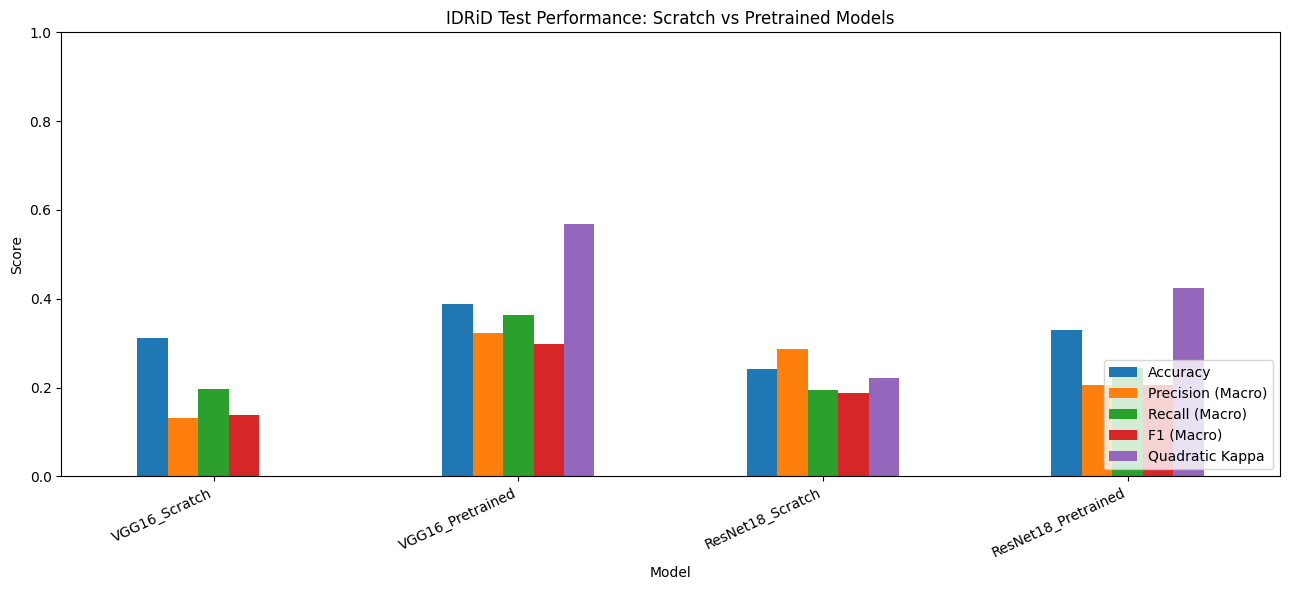

Ranking by test macro F1:


,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),Quadratic Kappa
Model,,,,,
VGG16_Pretrained,0.3883,0.3222,0.3630,0.2990,0.5680
ResNet18_Pretrained,0.3301,0.2064,0.2441,0.2052,0.4247
ResNet18_Scratch,0.2427,0.2859,0.1949,0.1867,0.2205
VGG16_Scratch,0.3107,0.1302,0.1974,0.1388,-0.0361


In [26]:
metric_columns = [
    "Accuracy", "Precision (Macro)", "Recall (Macro)",
    "F1 (Macro)", "Quadratic Kappa"
]

ax = results_df[metric_columns].plot(
    kind="bar", figsize=(13, 6), ylim=(0, 1)
)
ax.set_title("IDRiD Test Performance: Scratch vs Pretrained Models")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Ranking by test macro F1:")
display(results_df.sort_values("F1 (Macro)", ascending=False).round(4))

## 13. Confusion matrices and class-wise reports


VGG16_Scratch
              precision    recall  f1-score   support

     Grade 0       0.35      0.21      0.26        34
     Grade 1       0.00      0.00      0.00         5
     Grade 2       0.30      0.78      0.43        32
     Grade 3       0.00      0.00      0.00        19
     Grade 4       0.00      0.00      0.00        13

    accuracy                           0.31       103
   macro avg       0.13      0.20      0.14       103
weighted avg       0.21      0.31      0.22       103



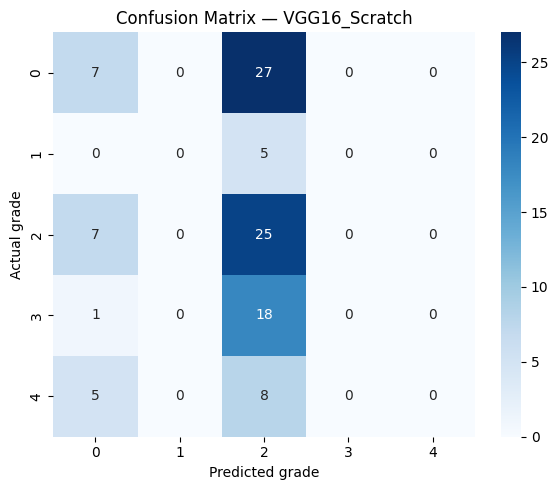


VGG16_Pretrained
              precision    recall  f1-score   support

     Grade 0       0.68      0.62      0.65        34
     Grade 1       0.00      0.00      0.00         5
     Grade 2       0.33      0.03      0.06        32
     Grade 3       0.23      0.47      0.31        19
     Grade 4       0.38      0.69      0.49        13

    accuracy                           0.39       103
   macro avg       0.32      0.36      0.30       103
weighted avg       0.42      0.39      0.35       103



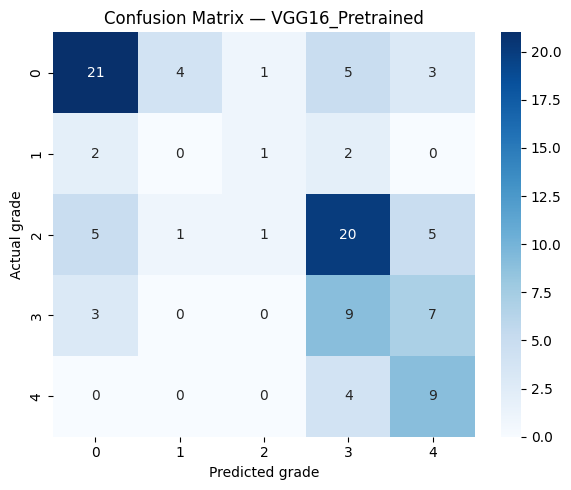


ResNet18_Scratch
              precision    recall  f1-score   support

     Grade 0       0.43      0.47      0.45        34
     Grade 1       0.00      0.00      0.00         5
     Grade 2       0.67      0.06      0.11        32
     Grade 3       0.21      0.21      0.21        19
     Grade 4       0.12      0.23      0.16        13

    accuracy                           0.24       103
   macro avg       0.29      0.19      0.19       103
weighted avg       0.40      0.24      0.24       103



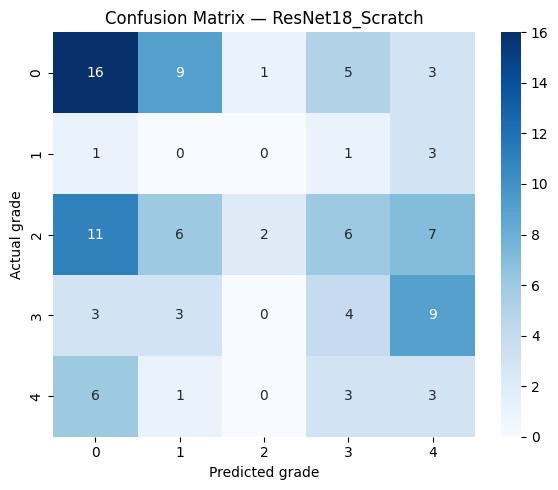


ResNet18_Pretrained
              precision    recall  f1-score   support

     Grade 0       0.45      0.74      0.56        34
     Grade 1       0.00      0.00      0.00         5
     Grade 2       0.29      0.12      0.17        32
     Grade 3       0.12      0.05      0.07        19
     Grade 4       0.17      0.31      0.22        13

    accuracy                           0.33       103
   macro avg       0.21      0.24      0.21       103
weighted avg       0.28      0.33      0.28       103



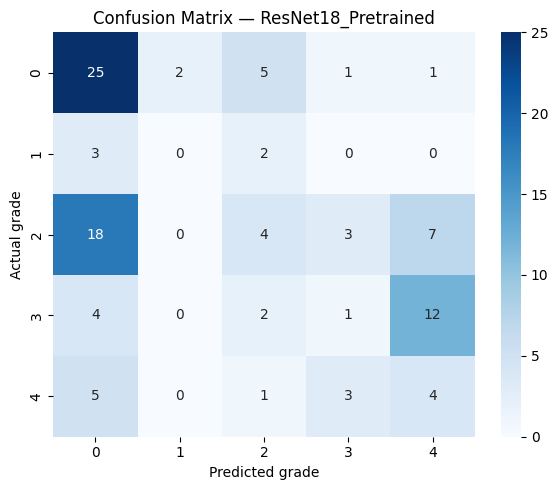

In [27]:
for name, (y_true, y_pred, y_prob) in test_predictions.items():
    print("\n", "="*70)
    print(name)
    print(classification_report(
        y_true, y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "Grade 0", "Grade 1", "Grade 2", "Grade 3", "Grade 4"
        ],
        zero_division=0
    ))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4])
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=[0, 1, 2, 3, 4],
        yticklabels=[0, 1, 2, 3, 4]
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted grade")
    plt.ylabel("Actual grade")
    plt.tight_layout()
    plt.show()

## 14. Compare scratch vs pretrained initialisation

In [28]:
comparison_rows = []
for architecture in ["VGG16", "ResNet18"]:
    scratch_name = f"{architecture}_Scratch"
    pretrained_name = f"{architecture}_Pretrained"

    row = {"Architecture": architecture}
    for metric in metric_columns:
        row[f"Scratch {metric}"] = results_df.loc[scratch_name, metric]
        row[f"Pretrained {metric}"] = results_df.loc[pretrained_name, metric]
        row[f"Difference {metric}"] = (
            results_df.loc[pretrained_name, metric]
            - results_df.loc[scratch_name, metric]
        )
    comparison_rows.append(row)

transfer_comparison = pd.DataFrame(comparison_rows).set_index("Architecture")
display(transfer_comparison.round(4))

,Scratch Accuracy,Pretrained Accuracy,Difference Accuracy,Scratch Precision (Macro),Pretrained Precision (Macro),Difference Precision (Macro),Scratch Recall (Macro),Pretrained Recall (Macro),Difference Recall (Macro),Scratch F1 (Macro),Pretrained F1 (Macro),Difference F1 (Macro),Scratch Quadratic Kappa,Pretrained Quadratic Kappa,Difference Quadratic Kappa
Architecture,,,,,,,,,,,,,,,
VGG16,0.3107,0.3883,0.0777,0.1302,0.3222,0.1919,0.1974,0.3630,0.1656,0.1388,0.2990,0.1602,-0.0361,0.5680,0.6041
ResNet18,0.2427,0.3301,0.0874,0.2859,0.2064,-0.0795,0.1949,0.2441,0.0492,0.1867,0.2052,0.0185,0.2205,0.4247,0.2042


## 15. Save results and model checkpoints

In [29]:
results_path = str(WORK_DIR / "idrid_model_comparison.csv")
results_df.to_csv(results_path)

comparison_path = str(WORK_DIR / "idrid_scratch_vs_pretrained.csv")
transfer_comparison.to_csv(comparison_path)

print("Saved results:", results_path)
print("Saved comparison:", comparison_path)
print("Saved checkpoints:")
for name, path in checkpoint_paths.items():
    print(name, "->", path)

Saved results: /content/outputs/idrid_model_comparison.csv
Saved comparison: /content/outputs/idrid_scratch_vs_pretrained.csv
Saved checkpoints:
VGG16_Scratch -> /content/outputs/checkpoints/VGG16_Scratch_best.pth
VGG16_Pretrained -> /content/outputs/checkpoints/VGG16_Pretrained_best.pth
ResNet18_Scratch -> /content/outputs/checkpoints/ResNet18_Scratch_best.pth
ResNet18_Pretrained -> /content/outputs/checkpoints/ResNet18_Pretrained_best.pth
